# Chapitre 8 - Cours 3 : horloges non fiables

Les applications posent sans cesse des questions de temps : cette requête a-t-elle
expiré ? quand ce cache périme-t-il ? qui a écrit en dernier ? Or chaque machine a sa
propre horloge, un quartz imparfait, synchronisé tant bien que mal par le réseau. Ce
notebook décortique les deux sortes d'horloges, ce que vaut leur synchronisation, et les
dangers de s'y fier pour **ordonner** des événements. Il couvre la section *Unreliable
Clocks* : *Monotonic Versus Time-of-Day Clocks*, *Clock Synchronization and Accuracy* et
*Relying on Synchronized Clocks* (*Timestamps for ordering events*, *Clock readings have a confidence interval*, *Synchronized clocks for global snapshots*).

**Plan.**

1. Mesurer une durée, dater un instant.
2. Horloge calendaire et horloge monotone.
3. Synchronisation et précision : dérive, NTP, secondes intercalaires.
4. Horodater pour ordonner : le piège de « la dernière écriture gagne ».
5. Lectures d'horloge avec intervalle de confiance, et instantanés globaux.

In [1]:
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch

from ddia import distsys as ds
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.requirements import plain_log_axis
from ddia.sim import Clock, Network, Node
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

## 1. Mesurer une durée, dater un instant (section *Unreliable Clocks*)

Le livre liste huit questions typiques ; elles se répartissent en deux familles.

| question | nature |
|---|---|
| cette requête a-t-elle expiré ? | **durée** |
| quel est le p99 du temps de réponse ? | **durée** |
| combien de requêtes par seconde ces cinq dernières minutes ? | **durée** |
| combien de temps l'utilisateur est-il resté sur le site ? | **durée** |
| quand cet article a-t-il été publié ? | **instant** |
| à quelle date et quelle heure envoyer le courriel de rappel ? | **instant** |
| quand cette entrée du cache expire-t-elle ? | **instant** |
| quel est l'horodatage de ce message d'erreur dans le journal ? | **instant** |

Dans un système distribué, le temps est délicat pour deux raisons : la communication
n'est pas instantanée (un message est reçu **après** son envoi, mais on ne sait pas
**combien** après, cours 2), et chaque machine a sa propre horloge matérielle,
généralement un **oscillateur à quartz**, légèrement trop rapide ou trop lent. Le
protocole **NTP** (Network Time Protocol) permet de recaler les horloges sur des
serveurs, eux-mêmes calés sur une source plus précise (récepteur GPS).

Python expose les deux sortes d'horloges des systèmes d'exploitation. Interrogeons-les
sur cette machine :

In [2]:
infos = []
for nom, role in [("time", "calendaire (time.time)"), ("monotonic", "monotone (time.monotonic)"),
                  ("perf_counter", "monotone haute résolution (time.perf_counter)")]:
    i = time.get_clock_info(nom)
    infos.append(dict(horloge=role, implémentation=i.implementation, résolution_s=i.resolution,
                      ajustable=i.adjustable, monotone=i.monotonic))
pd.DataFrame(infos).set_index("horloge")

,implémentation,résolution_s,ajustable,monotone
horloge,,,,
calendaire (time.time),clock_gettime(CLOCK_REALTIME),1.0000e-09,True,False
monotone (time.monotonic),clock_gettime(CLOCK_MONOTONIC),1.0000e-09,False,True
monotone haute résolution (time.perf_counter),clock_gettime(CLOCK_MONOTONIC),1.0000e-09,False,True


Sous Linux, `time.time()` lit `CLOCK_REALTIME` : elle est **ajustable** (NTP ou un
administrateur peuvent la modifier) et **non monotone**. `time.monotonic()` lit
`CLOCK_MONOTONIC` : jamais ajustée par sauts, toujours croissante. La résolution affichée
(la nanoseconde) ne dit rien de l'**exactitude**, comme on va le voir.

> **À retenir.** Une durée et un instant sont deux questions différentes, qui
> appellent deux horloges différentes. Aucune des deux n'est partagée entre machines.

## 2. Horloge calendaire et horloge monotone (section *Monotonic Versus Time-of-Day Clocks*)

**L'horloge calendaire** (time-of-day, ou wall-clock) donne la date et l'heure : le nombre
de secondes depuis l'**époque** (minuit UTC le 1er janvier 1970, sans compter les secondes
intercalaires). Synchronisée par NTP, elle permet en principe de comparer des
horodatages de machines différentes. Mais si l'horloge locale est trop en avance sur le
serveur NTP, elle peut être **recalée d'un coup** et sembler **reculer** dans le temps ;
les secondes intercalaires provoquent des sauts semblables (et les changements d'heure
d'été aussi, sauf à travailler en UTC). Elle est donc **impropre à mesurer une durée**.

**L'horloge monotone** est un chronomètre : sa valeur absolue n'a pas de sens (par
exemple, des nanosecondes depuis le démarrage), seule la **différence** entre deux
lectures en a, et elle ne recule jamais. Comparer les horloges monotones de deux machines
n'a aucun sens. NTP peut seulement en modifier légèrement la **fréquence** (« slewing »,
au plus 0,05 %) s'il constate que le quartz va trop vite ou trop lentement.

Simulons six heures d'une horloge calendaire (`ds.tod_clock_trace`) : quartz qui dérive
de 200 ppm, synchronisation NTP toutes les 10 minutes avec une erreur d'estimation de
5 ms ; si l'écart estimé dépasse 128 ms, NTP **recale d'un coup** ; sinon il corrige
progressivement par ralentissement (au plus 500 ppm).

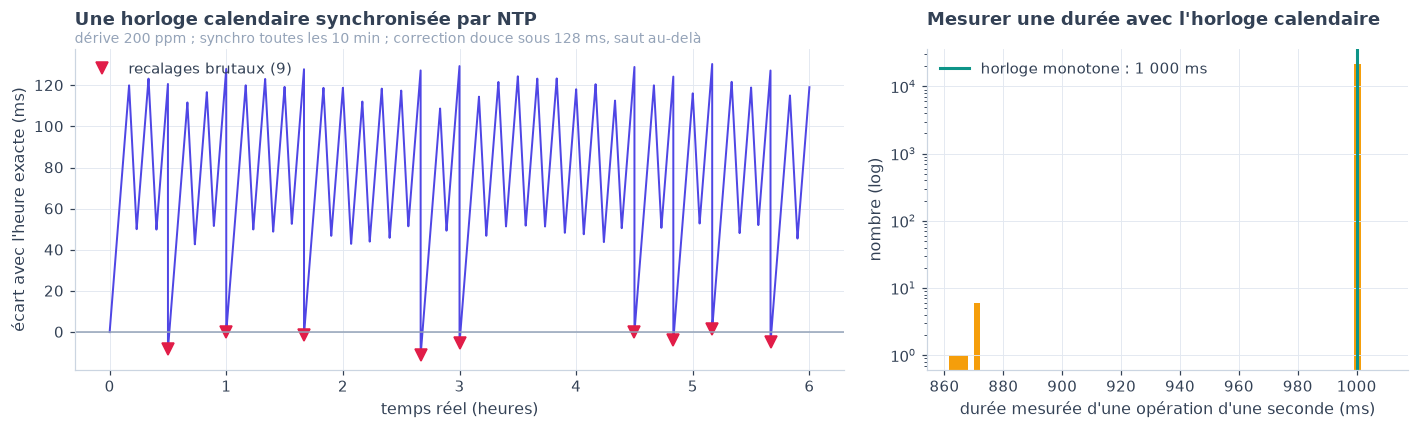

durée mesurée : min 861 ms, max 1000.2 ms ; 0.04% des mesures fausses de plus de 1 ms


In [3]:
tr = ds.tod_clock_trace(duration=6 * 3600, dt=1.0, drift_ppm=200, sync_every=600, sync_error_ms=5,
                        step_threshold_ms=128, seed=4)
t_h = tr["t"] / 3600
off = tr["offset_ms"]
# durée d'une opération d'une seconde mesurée avec l'horloge calendaire
mes = 1000 + np.diff(off)                              # ms
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax = axes[0]
ax.plot(t_h, off, color=INDIGO, lw=1.3)
j = np.flatnonzero(tr["jumps"])
ax.plot(t_h[j], off[j], "v", color=ROSE, ms=8, label=f"recalages brutaux ({j.size})")
ax.axhline(0, color=GRAY, lw=1)
ax.set_xlabel("temps réel (heures)"); ax.set_ylabel("écart avec l'heure exacte (ms)")
ax.set_title("Une horloge calendaire synchronisée par NTP")
subtitle(ax, "dérive 200 ppm ; synchro toutes les 10 min ; correction douce sous 128 ms, saut au-delà")
ax.legend(loc="upper left")
ax = axes[1]
ax.hist(mes, bins=np.linspace(min(mes.min(), 870), 1010, 70), color=AMBER, log=True)
ax.axvline(1000, color=TEAL, lw=2, label="horloge monotone : 1 000 ms")
ax.set_xlabel("durée mesurée d'une opération d'une seconde (ms)"); ax.set_ylabel("nombre (log)")
ax.set_title("Mesurer une durée avec l'horloge calendaire")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
print(f"durée mesurée : min {mes.min():.0f} ms, max {mes.max():.1f} ms ; "
      f"{np.mean(np.abs(mes - 1000) > 1):.2%} des mesures fausses de plus de 1 ms")

L'horloge s'écarte en dents de scie : 200 ppm, c'est 120 ms de dérive en dix minutes.
Quand l'écart estimé reste sous le seuil, NTP le résorbe en ralentissant l'horloge (les
pentes descendantes) ; quand il le dépasse, l'horloge est **recalée d'un coup** et
recule de plus d'un dixième de seconde. Une opération d'une seconde chronométrée à
cheval sur un recalage paraît durer moins de 0,9 s (elle pourrait même paraître durer un
temps **négatif** si le saut dépassait la seconde) ; pendant les phases de correction
douce, chaque mesure est fausse de quelques dixièmes de milliseconde. Pour mesurer un
délai d'expiration ou un temps de réponse, on utilise donc **toujours** l'horloge
monotone (`time.monotonic()` en Python, `System.nanoTime()` en Java,
`clock_gettime(CLOCK_MONOTONIC)` sous Linux). Sur un serveur à plusieurs processeurs,
le système doit même masquer le fait que chaque processeur a son propre compteur : il
est prudent de ne pas prendre la monotonie pour une garantie absolue.

> **À retenir.** L'horloge calendaire peut sauter en avant et en arrière : elle sert à
> dater, jamais à chronométrer. L'horloge monotone ne recule pas mais n'a de sens que
> sur une seule machine.